# 10 · 一句话的奖励，怎么更新每个 token？
上节课：一次抽中一个答案。本课：先生成文字，再生成结束符；整段回答完成后才评分。

**先只学第 1～3 步。** 主课在本机 CPU 运行，使用一个 12 参数的教学模型，不加载 Qwen。没有异步、装饰器或训练框架。最后另有 [Qwen 真实 token 对照](qwen_trace.ipynb)，用本机缓存验证概率计算。

我们固定只问「2 + 2 等于多少？只答一个数字」。这个模型不读取问题文字，只展示生成与更新机制，不能泛化到其他算术题。

## 1 · 输出从一个选项变成一个序列
三个输出 token：3、4、EOS。EOS 是“结束”这个动作，也要模型生成。
BOS 只是开始标记，不是本课要输出的答案。

本课模型是一张可训练分数表：上一 token 决定用哪一行 logits。真实 Transformer 会读取整个前文；这里用最简单的“只看上一个 token”模型。

In [1]:
import torch
torch.set_printoptions(precision=4, sci_mode=False)
names = ["3", "4", "<EOS>", "<BOS>"]
THREE, FOUR, EOS, BOS = 0, 1, 2, 3
# 4 个可能的输入 token × 3 个可能的输出 token = 12 个参数
model = torch.nn.Embedding(4, 3)
with torch.no_grad():
    model.weight.zero_()  # 初始每个输出 token 都是 1/3
print("参数表形状：", tuple(model.weight.shape))
for previous in [BOS, THREE, FOUR]:
    print("上一个 token =", names[previous],
          "→ 下一个 token 的概率 =", model(torch.tensor(previous)).softmax(0).detach())

参数表形状： (4, 3)
上一个 token = <BOS> → 下一个 token 的概率 = 

tensor([0.3333, 0.3333, 0.3333])
上一个 token = 3 → 下一个 token 的概率 = tensor([0.3333, 0.3333, 0.3333])
上一个 token = 4 → 下一个 token 的概率 = tensor([0.3333, 0.3333, 0.3333])


## 2 · 先走一遍指定序列：4 → EOS
这里故意指定这两个 token，方便逐项演算；还不是采样训练。
第二步的概率要以第一步已经生成的 4 为条件。

In [2]:
contexts = torch.tensor([BOS, FOUR])
tokens = torch.tensor([FOUR, EOS])
logits = model(contexts)                 # [2, 3]：两步各有三个输出分数
all_log_probs = logits.log_softmax(-1)   # [2, 3]
selected_log_probs = all_log_probs[torch.arange(2), tokens]  # [2]
for step in range(2):
    print(f"第 {step+1} 步：{names[contexts[step]]} → {names[tokens[step]]}",
          f"p={selected_log_probs[step].exp().item():.4f}",
          f"log p={selected_log_probs[step].item():.4f}")
sequence_log_prob = selected_log_probs.sum()
print("整句概率：", selected_log_probs.exp().prod().item())
print("整句 log 概率：", sequence_log_prob.item())
assert torch.allclose(sequence_log_prob.exp(), selected_log_probs.exp().prod())

第 1 步：<BOS> → 4 p=0.3333 log p=-1.0986
第 2 步：4 → <EOS> p=0.3333 log p=-1.0986
整句概率： 0.1111110970377922
整句 log 概率： -2.1972246170043945


两步的条件概率相乘：

$P(4,EOS)=P(4\mid BOS)P(EOS\mid4)=\frac13\times\frac13=\frac19$。

取自然对数后，乘法变成加法：

$\log P(4,EOS)=\log P(4\mid BOS)+\log P(EOS\mid4)$。

这里不能把第二步写成“不考虑前文的 EOS 概率”。

## 3 · 整句只给一次奖励
完整输出必须恰好是 4、EOS 才得 1 分。3、EOS 错了；4、4、EOS 多答了；只有 4 没结束也不合规。
我们的评分规则同时要求答对和及时结束。

In [3]:
def reward(sequence):
    return float(sequence == [FOUR, EOS])

for example in [[FOUR, EOS], [THREE, EOS], [FOUR, FOUR, EOS], [FOUR]]:
    print([names[i] for i in example], "→", reward(example))

baseline = 1 / 9  # 初始策略的精确平均奖励；下面固定它，不随本批回答变化
advantage = reward(tokens.tolist()) - baseline
token_losses = -advantage * selected_log_probs
loss = token_losses.sum()
print("整句优势：", advantage)
print("两个 token 的 loss 项：", token_losses.detach())
print("整句 loss：", loss.item())

['4', '<EOS>'] → 1.0
['3', '<EOS>'] → 0.0
['4', '4', '<EOS>'] → 0.0
['4'] → 0.0
整句优势： 0.8888888888888888
两个 token 的 loss 项： tensor([0.9765, 0.9765])
整句 loss： 1.9530885219573975


整句话只有一个优势 $A$，基础 REINFORCE 把它用于每个实际生成的 token：

$L=-A\sum_t\log p_t=\sum_t(-A\log p_t)$。

这不等于给整句话发了两次奖励。概率本来就是连乘，log 概率本来就是求和。
这个方法也没有准确判定“每个 token 各有多少功劳”；整句打分是粗粒度反馈。

## 4 · 每个 token 的梯度最后加到参数上
仍然只演算刚才指定的序列，不执行 step。选中的 token 得到怎样的梯度，可沿用上节的 A × (p − one_hot)。
EOS 也参与求导：它是学习何时停下的信号。

In [4]:
model.zero_grad()
loss.backward()
print("BOS 行的梯度（第一步）：", model.weight.grad[BOS])
print("4   行的梯度（第二步）：", model.weight.grad[FOUR])
print("3   行的梯度（本序列没用）：", model.weight.grad[THREE])
expected_first = advantage * (torch.ones(3)/3 - torch.tensor([0., 1., 0.]))
expected_second = advantage * (torch.ones(3)/3 - torch.tensor([0., 0., 1.]))
assert torch.allclose(model.weight.grad[BOS], expected_first)
assert torch.allclose(model.weight.grad[FOUR], expected_second)
print("手算梯度与 backward 一致。还没有更新参数。")

BOS 行的梯度（第一步）： tensor([ 0.2963, -0.5926,  0.2963])
4   行的梯度（第二步）： tensor([ 0.2963,  0.2963, -0.5926])
3   行的梯度（本序列没用）： tensor([0., 0., 0.])
手算梯度与 backward 一致。还没有更新参数。


## 5 · 真正采样：每次生成一个 token
从 BOS 开始，抽到什么，就把它作为下一次的输入。遇到 EOS 立刻停止；否则最多生成 3 个 token。
这个函数返回实际生成的下标列表，以及带计算图的各步 log 概率。没有通过正确答案替模型选择 token。

In [5]:
def sample_answer(current_model):
    previous = BOS
    sequence = []
    log_probs = []
    for position in range(3):
        next_logits = current_model(torch.tensor(previous))
        distribution = torch.distributions.Categorical(logits=next_logits)
        action = distribution.sample()
        sequence.append(action.item())
        log_probs.append(distribution.log_prob(action))
        previous = action.item()
        if previous == EOS:
            break
    return sequence, torch.stack(log_probs)

torch.manual_seed(23)
for attempt in range(6):
    sequence, lp = sample_answer(model)
    print([names[i] for i in sequence], "奖励", reward(sequence),
          "有效 token 数", len(lp))

['4', '3', '3'] 奖励 0.0 有效 token 数 3
['4', '4', '<EOS>'] 奖励 0.0 有效 token 数 3
['<EOS>'] 奖励 0.0 有效 token 数 1
['<EOS>'] 奖励 0.0 有效 token 数 1
['<EOS>'] 奖励 0.0 有效 token 数 1
['4', '4', '3'] 奖励 0.0 有效 token 数 3


## 6 · 一批 32 个回答，更新一次
每个回答先把自己的 token loss 求和，再对 32 个回答求平均。这样每条回答在批次平均中占一份。
不能把变长的回答拼起来后随意改成所有 token 的平均，那会改变梯度的缩放方式。

我们用列表保留真实长度：没有 padding；EOS 之后的内容根本没有采样，因此不用加入 loss。
若以后改成批量补齐，必须屏蔽 padding、EOS 后的部分以及非模型生成的提示词。

In [6]:
torch.manual_seed(31)
opt = torch.optim.SGD(model.parameters(), lr=0.3)
answer_losses = []
batch_rewards = []
for attempt in range(32):
    sequence, lp = sample_answer(model)
    score = reward(sequence)
    answer_losses.append(-(score - baseline) * lp.sum())
    batch_rewards.append(score)

batch_loss = torch.stack(answer_losses).mean()
weights_before = model.weight.detach().clone()
opt.zero_grad()           # 清除第 4 步演算留下的梯度
batch_loss.backward()
batch_gradient = model.weight.grad.detach().clone()
opt.step()
print("本批正确回答数：", int(sum(batch_rewards)), "/ 32")
print("整批平均 loss：", batch_loss.item())
print("BOS 行更新前：", weights_before[BOS])
print("BOS 行梯度：", batch_gradient[BOS])
print("BOS 行更新后：", model.weight.detach()[BOS])
assert torch.allclose(model.weight.detach(), weights_before - 0.3 * batch_gradient)

本批正确回答数： 4 / 32
整批平均 loss： 0.034331630915403366
BOS 行更新前： tensor([0., 0., 0.])
BOS 行梯度： tensor([ 0.0428, -0.0926,  0.0498])
BOS 行更新后： tensor([-0.0128,  0.0278, -0.0149])


## 7 · 从头训练 120 步，看完整答案概率
重新初始化，不接着上一格训练。每批重新采样 32 个完整回答。
我们可以精确计算“输出 4 后立即结束”的概率，这是这个小模型的可枚举特例。

In [7]:
def success_probability(current_model):
    with torch.no_grad():
        p4 = current_model(torch.tensor(BOS)).softmax(0)[FOUR]
        pend = current_model(torch.tensor(FOUR)).softmax(0)[EOS]
    return p4.item(), pend.item(), (p4 * pend).item()

torch.manual_seed(41)
trained = torch.nn.Embedding(4, 3)
with torch.no_grad():
    trained.weight.zero_()
optimizer = torch.optim.SGD(trained.parameters(), lr=0.3)
history = [success_probability(trained)]
sampled_rewards = []
for step in range(120):
    losses = []
    scores = []
    for attempt in range(32):
        sequence, lp = sample_answer(trained)
        score = reward(sequence)
        losses.append(-(score - baseline) * lp.sum())
        scores.append(score)
    objective = torch.stack(losses).mean()
    optimizer.zero_grad()
    objective.backward()
    optimizer.step()
    history.append(success_probability(trained))
    sampled_rewards.append(sum(scores) / 32)

print(f"完整正确回答概率：{history[0][2]:.4f} → {history[-1][2]:.4f}")
print("最后的 P(4|BOS)、P(EOS|4)、两者乘积：", history[-1])
print("只学一道固定题，不代表获得通用加法能力。")
assert history[-1][2] > history[0][2]

完整正确回答概率：0.1111 → 0.9459
最后的 P(4|BOS)、P(EOS|4)、两者乘积： (0.9724528789520264, 0.9726455807685852, 0.9458519816398621)
只学一道固定题，不代表获得通用加法能力。


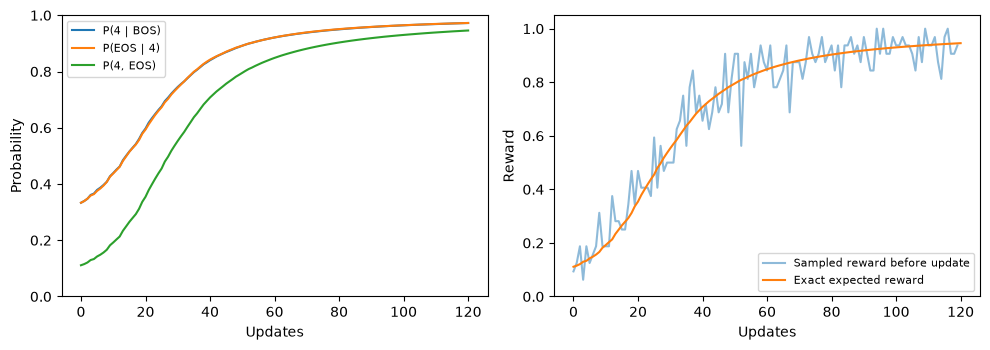

In [8]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for index, label in enumerate(["P(4 | BOS)", "P(EOS | 4)", "P(4, EOS)"]):
    axes[0].plot([h[index] for h in history], label=label)
axes[0].set(xlabel="Updates", ylabel="Probability", ylim=(0, 1))
axes[0].legend(fontsize=8)
axes[1].plot(range(120), sampled_rewards, alpha=0.5, label="Sampled reward before update")
axes[1].plot(range(121), [h[2] for h in history], label="Exact expected reward")
axes[1].set(xlabel="Updates", ylabel="Reward", ylim=(0, 1.05))
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8 · 接回 Qwen：相同的概率规则，不同的模型
| 这份课件 | 真正的大模型 |
|---|---|
| 上一个 token 查一行参数 | 整段前文通过 Transformer 计算 logits |
| 只有 3 个可输出 token | tokenizer 定义的大词表 |
| 只训练 12 个参数 | 更新模型权重或 LoRA 参数 |
| 生成后给一次奖励 | 可以给最终回答或中间步骤评分 |
| 对真实生成的 token log 概率求和 | 同样成立，但还要处理批次、长度和停止位置 |

在 Transformer 中，各步共用同一套网络权重。每步梯度通过网络反向传播，对同一参数的贡献会累加。给整句负奖励并不证明每个 token 都错了，这是奖励归因的难点。

继续打开 [qwen_trace.ipynb](qwen_trace.ipynb)：实际采样 Qwen，查看输出 token、条件概率和整句 log 概率。该文件只演示推理及评分，没有更新 Qwen 权重。

本课没有实现 PPO / GRPO、KL 约束、奖励模型或价值网络。下一课再解释为何需要限制更新幅度，以及同题多个回答如何比较。

来源：[基础策略梯度与基准](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)。

**自己解释：** 为什么结束符也要有梯度？为什么不能只更新最后一个 token？“4、4、EOS”虽然包含 4，为什么仍然是零分？